# Get h5ad of different species

*Harpegnathos saltator*

In [34]:
%%bash

ln -sf "/home/liuzhiyu/Projects/neo_caste/anno_cells/Sheng_SA_2020_Hsal/Hsal50.h5ad" "./matrix/Hsal50.h5ad"
# The 2021 Harpegnathos saltator dataset; obtained the RDS file by contacting the authors, and converted it to h5ad format.

*Apis mellifera*

In [ ]:
%%bash

wget -O "./matrix/GSE184507.tar" "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE184507"

In [ ]:
# merge the 2022 Apis mellifera dataset from GEO (GSE184507_RAW.tar) into a single h5ad file
import scanpy as sc
import anndata as ad
from pathlib import Path

raw_dir = Path("./matrix/GSE184507_RAW")
prefixes = sorted(p.name[: -len("matrix.mtx.gz")] for p in raw_dir.glob("*matrix.mtx.gz"))

adatas = [
    sc.read_10x_mtx(raw_dir, prefix=p, var_names="gene_symbols", gex_only=True)
    for p in prefixes
]

adata = ad.concat(
    adatas,
    join="outer",
    label="sample",
    keys=[p[:-1] for p in prefixes],
    index_unique="-",
)
adata.write_h5ad("./matrix/GSE184507.h5ad")
adata

In [ ]:
adata.obs
# 141,510 rows

,sample
AAACCCAAGAGCCTGA-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGAGTCACG-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGCACTCGC-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGCGCACAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGCGTCGAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1
...,...
TTTGTTGTCGGCTTGG-1-GSM5590458_scQueen2,GSM5590458_scQueen2
TTTGTTGTCTACCCAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2
TTTGTTGTCTCACTCG-1-GSM5590458_scQueen2,GSM5590458_scQueen2
TTTGTTGTCTCCTGAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2


In [ ]:
%%bash
# adata does not contain annotations; these were obtained subsequently by contacting the original authors of iScience (2022).
ln -sf "/home/liuzhiyu/Projects/neo_caste/anno_cells/Zhang_iScience_2022_Amel/metadata/metadata.csv" "./metadata/metadata.csv"

In [20]:
import pandas as pd

Amel_anno = pd.read_csv("./metadata/metadata.csv")
Amel_anno # 115169 rows

/tmp/ipykernel_102804/649958447.py:3: DtypeWarning: Columns (5,7) have mixed types. Specify dtype option on import or set low_memory=False.
  Amel_anno = pd.read_csv("./metadata/metadata.csv")


,Unnamed: 0,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,f,n,q,integrated_snn_res.1,seurat_clusters,type,cell_type
0,F1_sc_AAACCCAAGAGCCTGA-1,F1,4938,2284,5.548805,F,NaN,NaN,24,24,F,UNs
1,F1_sc_AAACCCAAGAGTCACG-1,F1,2181,1277,7.473636,F,NaN,NaN,9,9,F,KCs
2,F1_sc_AAACCCAAGCACTCGC-1,F1,5417,2227,12.017722,F,NaN,NaN,6,6,F,OPNs
3,F1_sc_AAACCCAAGCGCACAA-1,F1,5231,2255,6.652648,F,NaN,NaN,25,25,F,Glial cells
4,F1_sc_AAACCCAAGGCCCGTT-1,F1,6388,2624,5.541641,F,NaN,NaN,34,34,F,KCs
...,...,...,...,...,...,...,...,...,...,...,...,...
115164,Q2_sc_TTTGTTGTCCGTGGCA-1,Q2,6349,2577,5.937943,NaN,NaN,Q,3,3,Q,UNs
115165,Q2_sc_TTTGTTGTCGGCTTGG-1,Q2,3377,1682,6.692330,NaN,NaN,Q,5,5,Q,KCs
115166,Q2_sc_TTTGTTGTCTACCCAC-1,Q2,1849,999,13.142239,NaN,NaN,Q,32,32,Q,Glial cells
115167,Q2_sc_TTTGTTGTCTCACTCG-1,Q2,5251,2194,4.532470,NaN,NaN,Q,11,11,Q,KCs


In [6]:
Amel_anno['Unnamed: 0'].unique()

array(['F1_sc_AAACCCAAGAGCCTGA-1', 'F1_sc_AAACCCAAGAGTCACG-1',
       'F1_sc_AAACCCAAGCACTCGC-1', ..., 'Q2_sc_TTTGTTGTCTACCCAC-1',
       'Q2_sc_TTTGTTGTCTCACTCG-1', 'Q2_sc_TTTGTTGTCTCTGGTC-1'],
      shape=(115169,), dtype=object)

In [22]:
# combine the annotations with the adata object
adata.obs.index

Index(['AAACCCAAGAGCCTGA-1-GSM5590453_scFoager1',
       'AAACCCAAGAGTCACG-1-GSM5590453_scFoager1',
       'AAACCCAAGCACTCGC-1-GSM5590453_scFoager1',
       'AAACCCAAGCGCACAA-1-GSM5590453_scFoager1',
       'AAACCCAAGCGTCGAA-1-GSM5590453_scFoager1',
       'AAACCCAAGGCCCGTT-1-GSM5590453_scFoager1',
       'AAACCCAAGGTCCGAA-1-GSM5590453_scFoager1',
       'AAACCCAAGTCTACCA-1-GSM5590453_scFoager1',
       'AAACCCAAGTTTGAGA-1-GSM5590453_scFoager1',
       'AAACCCACAAGAATGT-1-GSM5590453_scFoager1',
       ...
       'TTTGTTGGTTCAAGTC-1-GSM5590458_scQueen2',
       'TTTGTTGGTTGTTTGG-1-GSM5590458_scQueen2',
       'TTTGTTGTCCAGGACC-1-GSM5590458_scQueen2',
       'TTTGTTGTCCATGCAA-1-GSM5590458_scQueen2',
       'TTTGTTGTCCGTGGCA-1-GSM5590458_scQueen2',
       'TTTGTTGTCGGCTTGG-1-GSM5590458_scQueen2',
       'TTTGTTGTCTACCCAC-1-GSM5590458_scQueen2',
       'TTTGTTGTCTCACTCG-1-GSM5590458_scQueen2',
       'TTTGTTGTCTCCTGAC-1-GSM5590458_scQueen2',
       'TTTGTTGTCTCTGGTC-1-GSM5590458_scQueen2']

In [23]:
sample_map = {
    "GSM5590453_scFoager1": "F1", "GSM5590454_scFoager2": "F2",
    "GSM5590455_scNurse1":  "N1", "GSM5590456_scNurse2":  "N2",
    "GSM5590457_scQueen1":  "Q1", "GSM5590458_scQueen2":  "Q2",
}

barcode = adata.obs_names.str.rsplit("-", n=1).str[0] # AAACCCAAGAGCCTGA-1
code = adata.obs["sample"].astype(str).map(sample_map) # GSM...scFoager1 -> F1
adata.obs["amel_key"] = code + "_sc_" + barcode # F1_sc_AAACCCAAGAGCCTGA-1

adata.obs = adata.obs.join(Amel_anno.set_index("Unnamed: 0"), on="amel_key")

In [24]:
adata.obs[~adata.obs["orig.ident"].isna()]
# After removing NAs, 115,169 rows in total, matching Amel_anno;

,sample,amel_key,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,f,n,q,integrated_snn_res.1,seurat_clusters,type,cell_type
AAACCCAAGAGCCTGA-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGAGCCTGA-1,F1,4938.0,2284.0,5.548805,F,NaN,NaN,24.0,24.0,F,UNs
AAACCCAAGAGTCACG-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGAGTCACG-1,F1,2181.0,1277.0,7.473636,F,NaN,NaN,9.0,9.0,F,KCs
AAACCCAAGCACTCGC-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGCACTCGC-1,F1,5417.0,2227.0,12.017722,F,NaN,NaN,6.0,6.0,F,OPNs
AAACCCAAGCGCACAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGCGCACAA-1,F1,5231.0,2255.0,6.652648,F,NaN,NaN,25.0,25.0,F,Glial cells
AAACCCAAGGCCCGTT-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGGCCCGTT-1,F1,6388.0,2624.0,5.541641,F,NaN,NaN,34.0,34.0,F,KCs
...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTTGTCCGTGGCA-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCCGTGGCA-1,Q2,6349.0,2577.0,5.937943,NaN,NaN,Q,3.0,3.0,Q,UNs
TTTGTTGTCGGCTTGG-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCGGCTTGG-1,Q2,3377.0,1682.0,6.692330,NaN,NaN,Q,5.0,5.0,Q,KCs
TTTGTTGTCTACCCAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCTACCCAC-1,Q2,1849.0,999.0,13.142239,NaN,NaN,Q,32.0,32.0,Q,Glial cells
TTTGTTGTCTCACTCG-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCTCACTCG-1,Q2,5251.0,2194.0,4.532470,NaN,NaN,Q,11.0,11.0,Q,KCs


In [25]:
# In the original 2022 iScience article, the authors incorrectly labeled the mitochondrial genes; the "MT-" prefix has been removed in all instances here.
adata.var_names = adata.var_names.str.replace("^MT-", "", regex=True)
adata.var_names_make_unique()
adata.write_h5ad("./matrix/Amel_wll.h5ad")

*Drosophila melanogaster*

In [22]:
%%bash

wget -O "./matrix/Dmel.loom" "https://flybrain.aertslab.org/downloads/loom/Davie_Janssens_Koldere_et_al_2018_AdultBrain.loom"

--2026-10-08 23:11:22--  https://flybrain.aertslab.org/downloads/loom/Davie_Janssens_Koldere_et_al_2018_AdultBrain.loom


Resolving flybrain.aertslab.org (flybrain.aertslab.org)... 134.58.50.9
Connecting to flybrain.aertslab.org (flybrain.aertslab.org)|134.58.50.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 519015198 (495M)
Saving to: './matrix/Dmel.loom'

     0K .......... .......... .......... .......... ..........  0%  169K 50m3s
    50K .......... .......... .......... .......... ..........  0%  338K 37m32s
   100K .......... .......... .......... .......... ..........  0%  340K 33m18s
   150K .......... .......... .......... .......... ..........  0% 29.4M 25m2s
   200K .......... .......... .......... .......... ..........  0% 30.6M 20m5s
   250K .......... .......... .......... .......... ..........  0%  348K 20m47s
   300K .......... .......... .......... .......... ..........  0% 22.7M 17m52s
   350K .......... .......... .......... .......... ..........  0% 34.3M 15m40s
   400K .......... .......... .......... .......... ..........  0% 29.0M 13m57s
   450K ........

In [ ]:
import loompy
import anndata as ad
import pandas as pd

with loompy.connect("./matrix/Dmel.loom", validate=False) as ds:
    X = ds.layers[""].sparse().T.tocsr()                # cells × genes
    obs = pd.DataFrame(index=pd.Index(ds.ca["CellID"], name="CellID"))
    for k in ["ClusterID", "batch", "cell_type", "leiden",
              "n_counts", "n_genes", "percent_mito", "sample_id"]:
        obs[k] = ds.ca[k]
    var = pd.DataFrame(index=pd.Index(ds.ra["Gene"], name="Gene"))

Dmel = ad.AnnData(X=X, obs=obs, var=var)
Dmel

In [32]:
Dmel = ad.AnnData(X=X, obs=obs, var=var)
Dmel.write_h5ad("./matrix/Dmel.h5ad")

*Apis cerana*

In [33]:
%%bash

ln -sf "/home/liuzhiyu/Projects/neo_caste/anno_cells/Acer/matrix/01_Acer_transfromHY.h5ad" "./matrix/01_Acer_transfromHY.h5ad"

# Get Orthologs

In [ ]:
%%bash

cp "/home/liuzhiyu/Projects/neo_caste/Find_Ortholog/primary_transcripts/OrthoFinder/Results_Sep13/Orthologues/Orthologues_Apis_cerana/Apis_cerana__v__Apis_mellifera.tsv" "./orthologs/Apis_cerana__v__Apis_mellifera.tsv"
cp "/home/liuzhiyu/Projects/neo_caste/Find_Ortholog/primary_transcripts/OrthoFinder/Results_Sep13/Orthologues/Orthologues_Apis_cerana/Apis_cerana__v__Drosophila_melanogaster.tsv" "./orthologs/Apis_cerana__v__Drosophila_melanogaster.tsv"
cp "/home/liuzhiyu/Projects/neo_caste/Find_Ortholog/primary_transcripts/OrthoFinder/Results_Sep13/Orthologues/Orthologues_Apis_cerana/Apis_cerana__v__Harpegnathos_saltator.tsv" "./orthologs/Apis_cerana__v__Harpegnathos_saltator.tsv"

In [2]:
import pandas as pd

Acer_vs_Amel = pd.read_csv("./orthologs/Apis_cerana__v__Apis_mellifera.tsv", sep="\t")
Acer_vs_Dmel = pd.read_csv("./orthologs/Apis_cerana__v__Drosophila_melanogaster.tsv", sep="\t")
Acer_vs_Hsal = pd.read_csv("./orthologs/Apis_cerana__v__Harpegnathos_saltator.tsv", sep="\t")

In [3]:
def get_121_orthologs(df, sp1, sp2):
    df_121 = df[
        ~df[sp1].str.contains(",", na=False)
        & ~df[sp2].str.contains(",", na=False)
    ]
    return df_121

In [4]:
Acer_vs_Amel_121 = get_121_orthologs(Acer_vs_Amel, "Apis_cerana", "Apis_mellifera")
Acer_vs_Dmel_121 = get_121_orthologs(Acer_vs_Dmel, "Apis_cerana", "Drosophila_melanogaster")
Acer_vs_Hsal_121 = get_121_orthologs(Acer_vs_Hsal, "Apis_cerana", "Harpegnathos_saltator")

In [4]:
Acer_vs_Amel_121.to_csv("./orthologs/Acer_vs_Amel_121.tsv", sep="\t", index=False)
Acer_vs_Dmel_121.to_csv("./orthologs/Acer_vs_Dmel_121.tsv", sep="\t", index=False)
Acer_vs_Hsal_121.to_csv("./orthologs/Acer_vs_Hsal_121.tsv", sep="\t", index=False)

# Check .h5ad gene id/gene name

OrthoFinder results are based on the `gene_id` column in the GTF file; however, since `anndata.var.index` in `h5ad` files from different sources is not necessarily the `gene_id`, this issue is addressed here.

In [8]:
%%bash
# get GTF data
wget -O "./metadata/Apis_mellifera.gtf.gz" "https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/apis_mellifera/Apis_mellifera.Amel_HAv3.1.63.gtf.gz"
wget -O "./metadata/Harpegnathos_saltator.gtf.gz" "https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/harpegnathos_saltator_gca003227715v2rs/Harpegnathos_saltator_gca003227715v2rs.Hsal_v8.5.63.gtf.gz"
wget -O "./metadata/Drosophila_melanogaster.gtf.gz" "https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/drosophila_melanogaster/Drosophila_melanogaster.BDGP6.54.63.gtf.gz"

gunzip "./metadata/Apis_mellifera.gtf.gz"
gunzip "./metadata/Harpegnathos_saltator.gtf.gz"
gunzip "./metadata/Drosophila_melanogaster.gtf.gz"

--2026-10-09 03:01:03--  https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/apis_mellifera/Apis_mellifera.Amel_HAv3.1.63.gtf.gz
Resolving ftp.ensemblgenomes.ebi.ac.uk (ftp.ensemblgenomes.ebi.ac.uk)... 193.62.193.161
Connecting to ftp.ensemblgenomes.ebi.ac.uk (ftp.ensemblgenomes.ebi.ac.uk)|193.62.193.161|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6947613 (6.6M) [application/x-gzip]
Saving to: './metadata/Apis_mellifera.gtf.gz'

     0K .......... .......... .......... .......... ..........  0%  163K 41s
    50K .......... .......... .......... .......... ..........  1% 53.9M 21s
   100K .......... .......... .......... .......... ..........  2%  324K 20s
   150K .......... .......... .......... .......... ..........  2% 61.0M 15s
   200K .......... .......... .......... .......... ..........  3%  328K 16s
   250K .......... .......... .......... .......... ..........  4% 32.1M 13s
   300K .......... .......... .......... .......... ..........  5%

In [ ]:
%%bash
gppy txinfo -g "./metadata/Apis_mellifera.gtf" > "./metadata/Apis_mellifera.tsv"
gppy txinfo -g "./metadata/Harpegnathos_saltator.gtf" > "./metadata/Harpegnathos_saltator.tsv"
gppy txinfo -g "./metadata/Drosophila_melanogaster.gtf" > "./metadata/Drosophila_melanogaster.tsv"


cp "/home/liuzhiyu/Projects/neo_caste/ApisSCENIC/.subprojects/03_is_my_orthofinder_wrong/gtf/Apis_cerana.tsv" "./metadata/Apis_cerana.tsv"

# ↑ The GTF data for Apis cerana originated from GenBank rather than Ensembl; 
# due to format discrepancies that prevented direct conversion using gppy, 
# a version of the GTF that had been manually corrected and converted to TSV format was used instead.

In [5]:
Amel_gtf = pd.read_csv("./metadata/Apis_mellifera.tsv", sep="\t")
Acer_gtf = pd.read_csv("./metadata/Apis_cerana.tsv", sep="\t")
Hsal_gtf = pd.read_csv("./metadata/Harpegnathos_saltator.tsv", sep="\t")
Dmel_gtf = pd.read_csv("./metadata/Drosophila_melanogaster.tsv", sep="\t")

/tmp/ipykernel_29556/336244662.py:2: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  Acer_gtf = pd.read_csv("./metadata/Apis_cerana.tsv", sep="\t")


In [6]:
import scanpy as sc

Amel = sc.read_h5ad("./matrix/Amel_wll.h5ad")
Acer = sc.read_h5ad("./matrix/01_Acer_transfromHY.h5ad")
Dmel = sc.read_h5ad("./matrix/Dmel.h5ad")
Hsal = sc.read_h5ad("./matrix/Hsal50.h5ad")

In [7]:
Amel_set = set(Amel.var.index)
Dmel_set = set(Dmel.var.index)
Hsal_set = set(Hsal.var.index)

In [8]:
Amel_121_set = set(Acer_vs_Amel_121["Apis_mellifera"].to_list())
Dmel_121_set = set(Acer_vs_Dmel_121["Drosophila_melanogaster"].to_list())
Hsal_121_set = set(Acer_vs_Hsal_121["Harpegnathos_saltator"].to_list())

In [9]:
Amel_gid_set = set(Amel_gtf["gene_id"].to_list())
Acer_gid_set = set(Acer_gtf["gene_id"].to_list())
Hsal_gid_set = set(Hsal_gtf["gene_id"].to_list())
Dmel_gid_set = set(Dmel_gtf["gene_id"].to_list())

目前已知，XXX_121_set 是特定物种与 *A. cerana* 一对一同源基因中，该物种基因的集合；XXX_set 是其他文章提供的表达矩阵中，该物种基因的集合；XXX_gid_set 是该物种 GTF 中，gene_id 列基因的集合。已知同源基因的计算是基于最新注释的，因此 XXX_121_set 一定是 XXX_gid_set 的子集。

但目前不确定的是 XXX_set，因为其对应的表达矩阵来自几年前的文章，不一定使用最新版的基因组注释。如果 XXX_set 不是 XXX_gid_set 的子集（或者说，XXX_set 中存在 XXX_gid_set 中没有的基因），可能会导致 XXX_121_set 与 XXX_set 的交集偏少，因此需核查 XXX_set 与 XXX_gid_set 的关系。

It is established that `XXX_121_set` represents the set of genes from a specific species involved in one-to-one orthologous pairs with *A. cerana*; `XXX_set` represents the set of genes from that species found in an expression matrix from a previous study; and `XXX_gid_set` represents the set of genes listed in the `gene_id` column of that species' GTF file. Since the orthologous gene identification was based on the latest annotation, `XXX_121_set` is necessarily a subset of `XXX_gid_set`.

However, the status of `XXX_set` is uncertain because the corresponding expression matrix originates from a study published several years ago and may not utilize the most recent genome annotation. If `XXX_set` is not a subset of `XXX_gid_set` (i.e., if `XXX_set` contains genes absent from `XXX_gid_set`), the intersection between `XXX_121_set` and `XXX_set` might be artificially low; therefore, the relationship between `XXX_set` and `XXX_gid_set` requires verification.

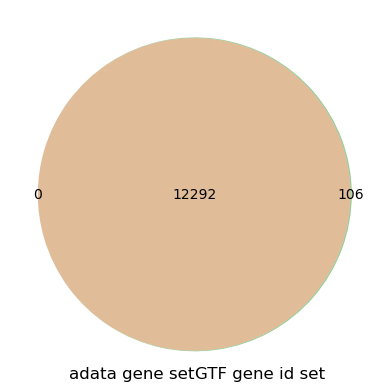

adata gene num: 12292
gtf gene num: 12398
adata ∩ gtf: 12292


In [10]:
from matplotlib_venn import venn2
import matplotlib.pyplot as plt

v = venn2([Amel_set, Amel_gid_set], set_labels=("adata gene set", "GTF gene id set"))
plt.show()

print(f"adata gene num: {len(Amel_set)}")
# print(f"ortho gene num: {len(Amel_121_set)}")
print(f"gtf gene num: {len(Amel_gid_set)}")

print(f"adata ∩ gtf: {len(Amel_set & Amel_gid_set)}")

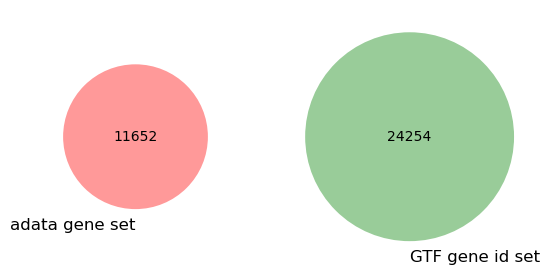

In [11]:
v = venn2([Dmel_set, Dmel_gid_set], set_labels=("adata gene set", "GTF gene id set"))
plt.show()
# It appears that the fruit fly adata.var.index uses the gene_name column from the GTF file rather than the gene_id column

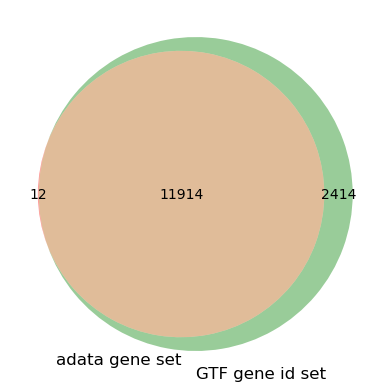

adata gene num: 11926
gtf gene num: 14328
adata ∩ gtf: 11914


In [12]:
v = venn2([Hsal_set, Hsal_gid_set], set_labels=("adata gene set", "GTF gene id set"))
plt.show()

print(f"adata gene num: {len(Hsal_set)}")
print(f"gtf gene num: {len(Hsal_gid_set)}")

print(f"adata ∩ gtf: {len(Hsal_set & Hsal_gid_set)}")

- *A. mellifera*: 0 genes of `adata gene set` not in `GTF gene id set`
- *D. melanogaster*: 11652 genes of `adata gene set` not in `GTF gene id set`
- *H. saltator*: 12 genes of `adata gene set` not in `GTF gene id set`

### Next, the reasons for this will be explored individually: 

*D. melanogaster*

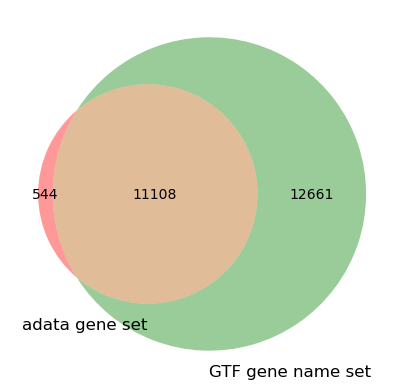

In [13]:
Dmel_gname_set = set(Dmel_gtf["gene_name"].to_list())
v = venn2([Dmel_set, Dmel_gname_set], set_labels=("adata gene set", "GTF gene name set"))
plt.show()
# Dmel_set is indeed derived from gene_name, yet it contains 544 unique genes; these are suspected to be obsolete gene names.

In [ ]:
%%bash

wget -O "./metadata/fbgn_annotation_ID_fb_2026_02.tsv.gz" "https://s3ftp.flybase.org/releases/current/precomputed_files/genes/fbgn_annotation_ID_fb_2026_02.tsv.gz"
wget -O "./metadata/fb_synonym_fb_2026_02.tsv.gz" "https://s3ftp.flybase.org/releases/current/precomputed_files/synonyms/fb_synonym_fb_2026_02.tsv.gz"
wget -O "./metadata/fbgn_annotation_ID_fb_2017_05.tsv.gz" "https://s3ftp.flybase.org/releases/FB2017_05/precomputed_files/genes/fbgn_annotation_ID_fb_2017_05.tsv.gz"

In [14]:
Dmel_not_in_gtf = Dmel_set - Dmel_gname_set

In [15]:
from functions.convert_davie import load_annotation, load_synonyms

fb17 = "./metadata/fbgn_annotation_ID_fb_2017_05.tsv.gz"
fb26 = "./metadata/fbgn_annotation_ID_fb_2026_02.tsv.gz"
syn  = "./metadata/fb_synonym_fb_2026_02.tsv.gz"

sym17, ann17 = load_annotation(fb17)
sym26, ann26 = load_annotation(fb26)
syn26 = load_synonyms(syn)

PRIORITY = [
    ("official_symbol@FB2017_r6.18", sym17),
    ("annotation_ID@FB2017_r6.18", ann17),
    ("official_symbol@FB2026", sym26),
    ("annotation_ID@FB2026", ann26),
    ("synonym@FB2026", syn26),
]

def map_symbol(g):
    """return (FBgn, source, n_candidates_at_best_level)"""
    for name, table in PRIORITY:
        hits = sorted(h for h in table.get(g, set()) if h.startswith("FBgn"))
        if hits:
            return hits[0], name, len(hits)
    return "", "UNMATCHED", 0

# ---------- map the set ----------
records = [map_symbol(g) for g in Dmel_not_in_gtf]

map_df = pd.DataFrame({
    "loom_gene_symbol": list(Dmel_not_in_gtf),
    "FBgn_ID": [r[0] for r in records],
    "match_source": [r[1] for r in records],
    "n_FBgn_candidates": [r[2] for r in records],
})

n_ok = (map_df.FBgn_ID != "").sum()
n_un = (map_df.FBgn_ID == "").sum()
n_multi = (map_df.n_FBgn_candidates > 1).sum()
print(f"  mapped: {n_ok}/{len(map_df)}  unmatched: {n_un}  multi-candidate: {n_multi}")
print(map_df.match_source.value_counts().to_string())
print(map_df[map_df.FBgn_ID == ""].to_string())

  mapped: 544/544  unmatched: 0  multi-candidate: 1
match_source
official_symbol@FB2017_r6.18    516
synonym@FB2026                   28
Empty DataFrame
Columns: [loom_gene_symbol, FBgn_ID, match_source, n_FBgn_candidates]
Index: []


In [16]:
map_df

,loom_gene_symbol,FBgn_ID,match_source,n_FBgn_candidates
0,Arf79F,FBgn0010348,official_symbol@FB2017_r6.18,1
1,CG17454,FBgn0039977,official_symbol@FB2017_r6.18,1
2,CG13773,FBgn0042092,official_symbol@FB2017_r6.18,1
3,CG43236,FBgn0262881,official_symbol@FB2017_r6.18,1
4,lncRNA:CR46194,FBgn0267913,synonym@FB2026,1
...,...,...,...,...
539,26-29-p,FBgn0250848,official_symbol@FB2017_r6.18,1
540,Pmp70,FBgn0031069,official_symbol@FB2017_r6.18,1
541,RpII15,FBgn0004855,official_symbol@FB2017_r6.18,1
542,CG7339,FBgn0036188,official_symbol@FB2017_r6.18,1


In [17]:
map_df.to_csv("./metadata/Dmel_not_in_gtf_mapping.csv", index=False)

In [20]:
Dmel_not_in_gtf_map_df = map_df[["loom_gene_symbol", "FBgn_ID"]].rename(columns={"loom_gene_symbol": "gene_name", "FBgn_ID": "gene_id"})

In [21]:
Dmel_in_gtf = Dmel_set & Dmel_gname_set
Dmel_in_gtf_map_df = Dmel_gtf[Dmel_gtf["gene_name"].isin(Dmel_in_gtf)][["gene_name", "gene_id"]].drop_duplicates()
Dmel_in_gtf_map_df

,gene_name,gene_id
3,CG15803,FBgn0038606
5,lncRNA:CR46035,FBgn0267702
6,side-III,FBgn0083949
7,CG5509,FBgn0038054
8,lncRNA:CR45203,FBgn0266730
...,...,...
41553,28SrRNA-Psi:CR40596,FBgn0085753
41556,pre-rRNA:CR45845,FBgn0267505
41560,5.8SrRNA-Psi:CR45849,FBgn0267509
41563,28SrRNA-Psi:CR45848,FBgn0267508


In [22]:
Dmel_all_map_df = pd.concat([Dmel_in_gtf_map_df, Dmel_not_in_gtf_map_df], ignore_index=True)
Dmel_all_map_df.to_csv("./metadata/Dmel_all_map.csv", index=False)
Dmel_all_map_df

,gene_name,gene_id
0,CG15803,FBgn0038606
1,lncRNA:CR46035,FBgn0267702
2,side-III,FBgn0083949
3,CG5509,FBgn0038054
4,lncRNA:CR45203,FBgn0266730
...,...,...
11647,26-29-p,FBgn0250848
11648,Pmp70,FBgn0031069
11649,RpII15,FBgn0004855
11650,CG7339,FBgn0036188


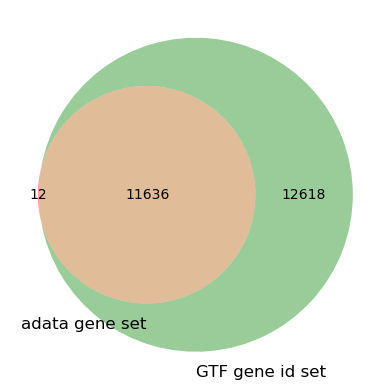

In [29]:
v = venn2([set(Dmel_all_map_df["gene_id"]), Dmel_gid_set], set_labels=("adata gene set", "GTF gene id set"))
plt.show()

In [ ]:
set(Dmel_all_map_df["gene_id"]) - Dmel_gid_set
#! Note that these 12 gene_ids were ultimately not found in the GTF file, and the reason for their absence could not be determined; therefore, we decided to use only the 11,636 genes found in the intersection for the Dmel vs. Acer MetaNeighbor analysis.

{'FBgn0026749',
 'FBgn0027585',
 'FBgn0029707',
 'FBgn0036660',
 'FBgn0037010',
 'FBgn0037726',
 'FBgn0050456',
 'FBgn0051320',
 'FBgn0051713',
 'FBgn0086058',
 'FBgn0284250',
 'FBgn0285962'}

In [36]:
name_to_id = dict(zip(Dmel_all_map_df["gene_name"], Dmel_all_map_df["gene_id"]))
Dmel.var["gene_id"] = Dmel.var.index.map(name_to_id)

In [37]:
Dmel.var["gene_name"] = Dmel.var.index
Dmel.var = Dmel.var.set_index("gene_id")
Dmel.var

,gene_name
gene_id,
FBgn0010339,128up
FBgn0020238,14-3-3epsilon
FBgn0004907,14-3-3zeta
FBgn0010340,140up
FBgn0085813,18SrRNA-Psi:CR41602
...,...
FBgn0287873,zip
FBgn0259789,zld
FBgn0052311,zormin


In [ ]:
Dmel.write_h5ad("./matrix/Dmel_FBgn.h5ad")

*H. saltator*